# **PUMP IT UP 1 - JAIME DE VERA MARTÍN**

---

---



## Me conecto a Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Instalo las librerías necesarias

In [ ]:
!pip install ydata-profiling

## Importo las librerías necesarias

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ydata_profiling import ProfileReport

from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import RandomizedSearchCV

from xgboost import XGBClassifier

## Me creo mis DataFrames principales y veo sus dimensiones

In [ ]:
# Tras observar el conjunto de datos, establezco ya el índice y convierto la fecha a formato DateTime
X_train = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TrainingSetValues.csv',
                      sep=',',
                      index_col='id',
                      parse_dates=['date_recorded'],
                      date_format='%Y-%m-%d')

y_train = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TrainingSetLabels.csv',
                      sep=',',
                      index_col='id')

X_test = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TestSetValues.csv',
                     sep=',',
                     index_col='id',
                     parse_dates=['date_recorded'],
                     date_format='%Y-%m-%d')

In [ ]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)

(59400, 39)
(59400, 1)
(14850, 39)


## **EDA INICIAL DE TRAIN**

In [ ]:
# Creo un DataFrame juntando train y su target
df_eda_1 = pd.merge(X_train, y_train, on='id')

In [ ]:
df_eda_1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 59400 entries, 69572 to 26348
Data columns (total 40 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   amount_tsh             59400 non-null  float64       
 1   date_recorded          59400 non-null  datetime64[ns]
 2   funder                 55763 non-null  object        
 3   gps_height             59400 non-null  int64         
 4   installer              55745 non-null  object        
 5   longitude              59400 non-null  float64       
 6   latitude               59400 non-null  float64       
 7   wpt_name               59398 non-null  object        
 8   num_private            59400 non-null  int64         
 9   basin                  59400 non-null  object        
 10  subvillage             59029 non-null  object        
 11  region                 59400 non-null  object        
 12  region_code            59400 non-null  int64         
 13  di

In [ ]:
df_eda_1

,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
id,,,,,,,,,,,,,,,,,,,,,
69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,Lake Nyasa,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,Lake Victoria,...,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,Pangani,...,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,Ruvuma / Southern Coast,...,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,Lake Victoria,...,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60739,10.0,2013-05-03,Germany Republi,1210,CES,37.169807,-3.253847,Area Three Namba 27,0,Pangani,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
27263,4700.0,2011-05-07,Cefa-njombe,1212,Cefa,35.249991,-9.070629,Kwa Yahona Kuvala,0,Rufiji,...,soft,good,enough,enough,river,river/lake,surface,communal standpipe,communal standpipe,functional
37057,0.0,2011-04-11,NaN,0,NaN,34.017087,-8.750434,Mashine,0,Rufiji,...,fluoride,fluoride,enough,enough,machine dbh,borehole,groundwater,hand pump,hand pump,functional


In [ ]:
df_eda_1.describe()

,amount_tsh,date_recorded,gps_height,longitude,latitude,num_private,region_code,district_code,population,construction_year
count,59400.000000,59400,59400.000000,59400.000000,5.940000e+04,59400.000000,59400.000000,59400.000000,59400.000000,59400.000000
mean,317.650385,2012-03-29 09:11:33.818181888,668.297239,34.077427,-5.706033e+00,0.474141,15.297003,5.629747,179.909983,1300.652475
min,0.000000,2002-10-14 00:00:00,-90.000000,0.000000,-1.164944e+01,0.000000,1.000000,0.000000,0.000000,0.000000
25%,0.000000,2011-04-01 00:00:00,0.000000,33.090347,-8.540621e+00,0.000000,5.000000,2.000000,0.000000,0.000000
50%,0.000000,2012-10-10 00:00:00,369.000000,34.908743,-5.021597e+00,0.000000,12.000000,3.000000,25.000000,1986.000000
75%,20.000000,2013-02-09 00:00:00,1319.250000,37.178387,-3.326156e+00,0.000000,17.000000,5.000000,215.000000,2004.000000
max,350000.000000,2013-12-03 00:00:00,2770.000000,40.345193,-2.000000e-08,1776.000000,99.000000,80.000000,30500.000000,2013.000000
std,2997.574558,NaN,693.116350,6.567432,2.946019e+00,12.236230,17.587406,9.633649,471.482176,951.620547


In [ ]:
profile = ProfileReport(df_eda_1, title="Informe de Perfil")
# Para visualizarlo en el Notebook:
#profile

# Para guardarlo en un archivo .html y no tener que estar ejecutándolo todo el rato:
#profile.to_file("reporte_eda_inicial.html")

Gracias al primer Análisis Exploratorio de Datos podemos ver varios problemas estructurales en los datos que debemos corregir antes de que cualquier algoritmo de Machine Learning pueda aprender de ellos:

1. **Variables inútiles:**
   * Eliminar filas duplicadas.
   * `recorded_by`: tiene cardinalidad 1 (el mismo valor en las 59.400 filas). Al ser una constante, no tiene poder predictivo.
   * `num_private`: el 98.7% de sus valores son ceros. Es una variable con varianza casi nula.
   * Columnas redundantes: el dataset tiene columnas que dicen exactamente lo mismo con distintos niveles de detalle como `extraction_type`, `extraction_type_group` y `extraction_type_class`. Mantenerlas todas genera multicolinealidad por lo que nos quedaremos solo con una por familia y eliminaremos el resto.

2. **Ceros encubiertos:**
   * La variable `construction_year` tiene más de 20.000 registros con el valor `0`. Es imposible que una instalación se construyera en el año cero; son valores nulos (`NaN`).
   * Variables como `longitude`, `population` y `gps_height` también presentan ceros imposibles por su contexto geográfico.

3. **Variables temporales:**
   * Los algoritmos no entienden las fechas en formato texto o calendario (`date_recorded`) así que extraeremos el año y el mes de registro y lo cruzaremos con el año de construcción para crear una nueva variable que sea la verdadera antigüedad de la instalación.

4. **Variables de alta cardinalidad:**
   * Hay columnas de texto que tienen miles de categorías distintas,así que las agruparemos, aunque no de la misma manera:
      - Geografía redundante (`subvillage`, `ward`): en este caso, como ya tenemos la región, el distrito, la latitud y la longitud, estas columnas sobran, por lo que las eliminaremos.
      - Nombres propios (`wpt_name`, `scheme_name`): son casi como IDs únicos. Aportan demasiado ruido, por lo que también las eliminaremos.
      - Organizaciones (`funder`, `installer`): aquí unas pocas grandes ONGs y el Gobierno hacen la mayoría de los pozos por lo que unificaremos el texto en minúsculas y aplicaremos la regla del "Top 20" para quedarnos con los gigantes, agrupando a los financiadores minoritarios en `'Other'`.

5. **Corrección de tipos de datos:**
   * Existen columnas numéricas que en realidad son categorías: `region_code` y `district_code`.
   Si dejamos estas variables como números, el modelo intentará hacer operaciones matemáticas con ellas, creyendo que el Distrito 5 es mayor o mejor que el Distrito 1, por lo que transformaremos estas columnas a tipo texto.

6. **Corregir strings y sincronizar con la variable objetivo:**
   * Asegurar que todas las columnas de texto restantes estén en minúsculas y no tengan espacios invisibles al principio o al final.
   * Sincronización: como vamos a eliminar 34 filas duplicadas solo en `X_train`, nuestra variable objetivo seguirá teniendo esas filas. Si no eliminamos esas mismas filas en `y_train` tendrán tamaños distintos.

## **LIMPIEZA DE DATOS**

In [ ]:
# 1. Eliminar variables inútiles

# Eliminar filas exactamente iguales
X_train.drop_duplicates(inplace=True)

# Eliminar columnas inútiles y redundantes
columnas_inutiles = ['recorded_by', 'num_private']

columnas_redundantes = [
    'extraction_type_group',
    'extraction_type_class',
    'payment_type',
    'quality_group',
    'quantity_group',
    'source_type',
    'source_class',
    'waterpoint_type_group',
    'management_group']

X_train.drop(columns=columnas_inutiles + columnas_redundantes, inplace=True)

In [ ]:
# 2. Reemplazar ceros encubiertos por NaNs
columnas_con_ceros = ['construction_year', 'longitude', 'population', 'gps_height']
X_train[columnas_con_ceros] = X_train[columnas_con_ceros].replace(0, np.nan)

In [ ]:
# 3. Extraemos el año y el mes de 'date_recorded', creamos la variable antigüedad y eliminamos 'date_recorded'
X_train['year_recorded'] = X_train['date_recorded'].dt.year
X_train['month_recorded'] = X_train['date_recorded'].dt.month

X_train['antiguedad'] = X_train['year_recorded'] - X_train['construction_year']

X_train.drop(columns=['date_recorded', 'construction_year'], inplace=True)

In [ ]:
# 4. Reducción de alta cardinalidad

    # A. Eliminar variables geográficas redundantes o nombres demasiado específicos
columnas_a_eliminar = ['wpt_name', 'subvillage', 'ward', 'scheme_name']
X_train.drop(columns=columnas_a_eliminar, inplace=True)

    # B. Estandarizar el texto de 'funder' y 'installer' y agrupar con el TOP 20
columnas_organizaciones = ['funder', 'installer']
for col in columnas_organizaciones:
    X_train[col] = X_train[col].astype(str).str.lower().str.strip()

top_n = 20
for col in columnas_organizaciones:
    top_categorias = X_train[col].value_counts().nlargest(top_n).index
    X_train[col] = X_train[col].where(X_train[col].isin(top_categorias), 'other')

In [ ]:
# 5. Corrección de falsas variables numéricas
columnas_falsos_numeros = ['region_code', 'district_code']
for col in columnas_falsos_numeros:
    X_train[col] = X_train[col].astype(str)

In [ ]:
# 6. Estandarizar strings y alinear X_train con y_train

# Estandarizamos todas las columnas que sean de tipo object
columnas_texto = X_train.select_dtypes(include=['object']).columns
for col in columnas_texto:
    X_train[col] = X_train[col].astype(str).str.lower().str.strip()

# Sincronizamos y_train para que tenga exactamente las mismas filas que X_train
y_train = y_train.loc[X_train.index]

## **EDA POST-LIMPIEZA**

1. RESUMEN DEL NUEVO DATASET:
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
Index: 59363 entries, 69572 to 26348
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   amount_tsh         59363 non-null  float64
 1   funder             59363 non-null  object 
 2   gps_height         38962 non-null  float64
 3   installer          59363 non-null  object 
 4   longitude          57587 non-null  float64
 5   latitude           59363 non-null  float64
 6   basin              59363 non-null  object 
 7   region             59363 non-null  object 
 8   region_code        59363 non-null  object 
 9   district_code      59363 non-null  object 
 10  lga                59363 non-null  object 
 11  population         38019 non-null  float64
 12  public_meeting     59363 non-null  object 
 13  scheme_management  59363 non-null  object 
 14  permit             59363 non-null  object 
 15  

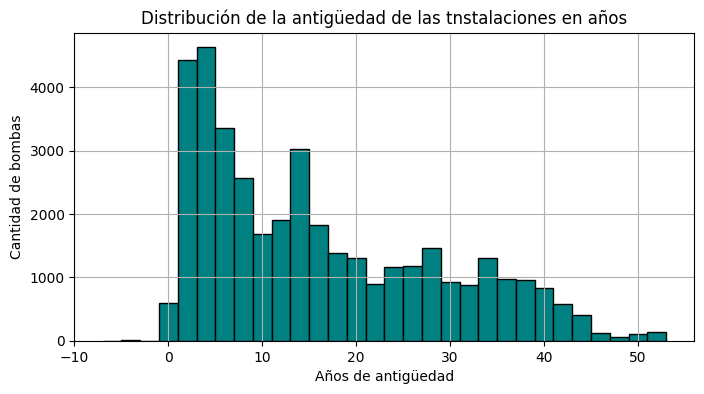

In [ ]:
print("1. RESUMEN DEL NUEVO DATASET:")
print("-" * 40)
X_train.info()

print("\n2. PORCENTAJE DE VALORES NULOS:")
print("-" * 40)
nulos_porcentaje = (X_train.isnull().sum() / len(X_train)) * 100
print(nulos_porcentaje[nulos_porcentaje > 0].sort_values(ascending=False))

print("\n3. VISTAZO A NUESTRA NUEVA VARIABLE 'ANTIGUEDAD':")
print("-" * 40)
print(X_train['antiguedad'].describe())

plt.figure(figsize=(8, 4))
X_train['antiguedad'].hist(bins=30, color='teal', edgecolor='black')
plt.title('Distribución de la antigüedad de las tnstalaciones en años')
plt.xlabel('Años de antigüedad')
plt.ylabel('Cantidad de bombas')
plt.show()

## **PREPROCESADO**

1. **Imputación numérica:** rellenaremos los nulos de variables como población o altitud usando la Mediana, evitando así que los outliers distorsionen el cálculo.
   * No todos los huecos los rellenaremos igual. Si a un pozo le falta su `longitude` o su `gps_height` (altitud), no podemos rellenarlo con la mediana de todo el país. Para las variables geográficas utilizaremos la mediana pero de los pozos que pertenezcan a su misma **Región**. Así aseguramos la coherencia espacial.
   * El resto (`population`, `antiguedad`) sí que los rellenaremos con la mediana global del entrenamiento.
2. **Imputación categórica:** rellenaremos los nulos de las variables de texto y booleanas. En lugar de inventar un dato, los rellenaremos con la etiqueta `'unknown'`. A veces, el hecho de que falte un dato es un patrón en sí mismo que el modelo debe aprender.
3. **Encoding:**
   * Mapeo ordinal: para variables con jerarquía como `quantity`, convertiremos los textos a números secuenciales respetando su orden lógico (de menos a más agua).
   * Frequency encoding: para variables con muchísimas categorías como `funder` o `installer`, sustituiremos el nombre por el número de veces que aparece en el dataset. Así el modelo distinguirá entre contratistas masivos y contratistas locales.
   * One-Hot Encoding: para el resto de variables descriptivas sin un orden claro y con pocas categorías crearemos dummies.

In [ ]:
# 1. Imputación numérica
columnas_geo = ['longitude', 'gps_height']
for col in columnas_geo:
    X_train[col] = X_train[col].fillna(X_train.groupby('region')[col].transform('median'))

columnas_general = ['population', 'antiguedad']
for col in columnas_general:
    mediana_col = X_train[col].median()
    X_train[col] = X_train[col].fillna(mediana_col)

  # Por si acaso alguna región no tuviera ningún dato de longitud, rellenamos los restos con la global
X_train['longitude'] = X_train['longitude'].fillna(X_train['longitude'].median())
X_train['gps_height'] = X_train['gps_height'].fillna(X_train['gps_height'].median())

In [ ]:
# 2. Imputación categórica
columnas_categoricas = X_train.select_dtypes(exclude=['number']).columns
for col in columnas_categoricas:
    if X_train[col].isnull().sum() > 0:
        X_train[col] = X_train[col].astype(str)
        X_train[col] = X_train[col].replace('nan', 'unknown')

In [ ]:
# 3. Encoding

    # A. Mapeo ordinal
diccionario_quantity = {
    'dry': 0,
    'unknown': 1,
    'insufficient': 2,
    'seasonal': 3,
    'enough': 4}

if 'quantity' in X_train.columns:
    X_train['quantity'] = X_train['quantity'].map(diccionario_quantity)

    # B. Frequency encoding
columnas_freq = ['funder', 'installer']
for col in columnas_freq:
    if col in X_train.columns:
        frecuencias = X_train[col].value_counts()
        X_train[col] = X_train[col].map(frecuencias)

    # C. One-Hot Encoding
columnas_dummy = X_train.select_dtypes(include=['object']).columns
X_train = pd.get_dummies(X_train, columns=columnas_dummy, drop_first=False)
X_train.columns = X_train.columns.astype(str)

## **EDA POST-PREPROCESADO**

In [ ]:
print("1. RESUMEN DE TIPOS DE DATOS:")
print("-" * 40)
print(X_train.dtypes.value_counts())

print("\n2. COMPROBACIÓN DE NULOS:")
print("-" * 40)
total_nulos = X_train.isnull().sum().sum()
print(f"Total de valores nulos en el dataset: {total_nulos}")

print("\n3. ESTRUCTURA FINAL DE LA MATRIZ:")
print("-" * 40)
X_train.head(5)

1. RESUMEN DE TIPOS DE DATOS:
----------------------------------------
bool       282
float64      6
int64        3
int32        2
Name: count, dtype: int64

2. COMPROBACIÓN DE NULOS:
----------------------------------------
Total de valores nulos en el dataset: 0

3. ESTRUCTURA FINAL DE LA MATRIZ:
----------------------------------------


,amount_tsh,funder,gps_height,installer,longitude,latitude,population,quantity,year_recorded,month_recorded,...,source_shallow well,source_spring,source_unknown,waterpoint_type_cattle trough,waterpoint_type_communal standpipe,waterpoint_type_communal standpipe multiple,waterpoint_type_dam,waterpoint_type_hand pump,waterpoint_type_improved spring,waterpoint_type_other
id,,,,,,,,,,,,,,,,,,,,,
69572,6000.0,26924,1390.0,23338,34.938093,-9.856322,109.0,4,2011,3,...,False,True,False,False,True,False,False,False,False,False
8776,0.0,26924,1399.0,23338,34.698766,-2.147466,280.0,2,2013,3,...,False,False,False,False,True,False,False,False,False,False
34310,25.0,26924,686.0,699,37.460664,-3.821329,250.0,4,2013,2,...,False,False,False,False,False,True,False,False,False,False
67743,0.0,1057,263.0,23338,38.486161,-11.155298,58.0,0,2013,1,...,False,False,False,False,False,True,False,False,False,False
19728,0.0,26924,1191.0,23338,31.130847,-1.825359,150.0,3,2011,7,...,False,False,False,False,True,False,False,False,False,False


## **MODELO PREDICTIVO RANDOM FOREST CLASSIFIER**

Una vez listo el detaset vamos a utilizar **Random Forest Classifier**. Este modelo es un "Ensemble", lo que significa que en lugar de crear un solo árbol de decisión, creará cientos de ellos y los hará votar para tomar la decisión final:
   * División de validación: separaremos nuestro `X_train` en dos trozos; un 80% para que el modelo estudie y un 20% reservado para hacerle un examen y comprobar su precisión real.
   * Fit: le pasaremos los datos al algoritmo para que descubra los patrones.
   * Evaluación: le pediremos que prediga el estado del 20% que reservamos y compararemos sus respuestas con la realidad.

In [ ]:
# A. Dividimos los datos para poder evaluar
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42)

# B. Entrenamos el modelo
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train_sub, y_train_sub)

# C. Evaluación
predicciones = modelo_rf.predict(X_val)
precision = accuracy_score(y_val, predicciones)
print("-" * 40)
print(f"ACCURACY (Precisión Global): {precision * 100:.2f}%")
print("-" * 40)

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


----------------------------------------
ACCURACY (Precisión Global): 80.22%
----------------------------------------


## **INTERPRETABILIDAD DEL MODELO RANDOM FOREST CLASSIFIER**

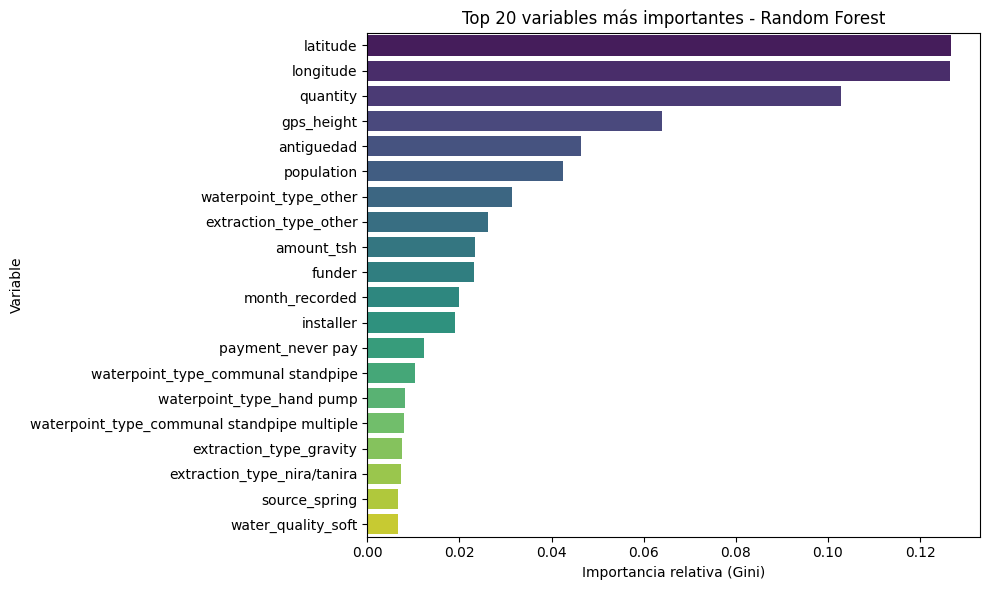

Las 20 variables principales explican el 71.89% de las decisiones del modelo.


In [ ]:
# 1. Extraemos las importancias y las emparejamos con los nombres de las columnas
importancias = modelo_rf.feature_importances_
nombres_variables = X_train_sub.columns

# 2. Creamos un DataFrame y lo ordenamos de mayor a menor importancia
df_importancias = pd.DataFrame({'Variable': nombres_variables, 'Importancia': importancias})
df_importancias = df_importancias.sort_values(by='Importancia', ascending=False)

# 3. Visualizamos el Top 20
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importancia',
    y='Variable',
    data=df_importancias.head(20),
    palette='viridis',
    hue='Variable',
    legend=False)
plt.title('Top 20 variables más importantes - Random Forest')
plt.xlabel('Importancia relativa (Gini)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

# Mostramos el porcentaje acumulado del Top 20
peso_top20 = df_importancias.head(20)['Importancia'].sum() * 100
print(f"Las 20 variables principales explican el {peso_top20:.2f}% de las decisiones del modelo.")

## **PREPACIÓN DE X_TEST**

In [ ]:
def pipeline_preprocesado_test(df_test_crudo, columnas_entrenamiento):
    df = df_test_crudo.copy()

    # 1. Salvaguarda de IDs (extraídos del índice)
    ids = df.index.copy()

    # 2. Ingeniería de variables
    df['antiguedad'] = df['date_recorded'].dt.year - df['construction_year']
    df.drop(columns=['date_recorded', 'construction_year'], inplace=True)

    # 3. Imputación Numérica
    for col in ['longitude', 'gps_height']:
        df[col] = df[col].fillna(df.groupby('region')[col].transform('median'))
        df[col] = df[col].fillna(df[col].median())

    for col in ['population', 'antiguedad']:
        df[col] = df[col].fillna(df[col].median())

    # 4. Imputación Categórica
    cols_cat = df.select_dtypes(exclude=['number']).columns
    for col in cols_cat:
        df[col] = df[col].astype(str).replace('nan', 'unknown')

    # 5. Codificación (Encoding)
    diccionario_quantity = {'dry': 0, 'unknown': 1, 'insufficient': 2, 'seasonal': 3, 'enough': 4}
    if 'quantity' in df.columns:
        df['quantity'] = df['quantity'].map(diccionario_quantity)

    for col in ['funder', 'installer']:
        if col in df.columns:
            df[col] = df[col].map(df[col].value_counts()).fillna(0)

    cols_ohe = df.select_dtypes(include=['object']).columns
    df = pd.get_dummies(df, columns=cols_ohe)

    # 6. Alineación de dimensiones
    df = df.reindex(columns=columnas_entrenamiento, fill_value=0)

    return df, ids


# EJECUCIÓN DEL PIPELINE
X_test_procesado, ids_test = pipeline_preprocesado_test(X_test, X_train.columns)

print(f"Dimensiones finales: {X_test_procesado.shape}")

Dimensiones finales: (14850, 293)


## **PREDICCIÓN Y EXPORTACIÓN RANDOM FOREST CLASSIFIER**

In [ ]:
predicciones = modelo_rf.predict(X_test_procesado)

df_submission = pd.DataFrame({
    'id': ids_test,
    'status_group': predicciones})

nombre_archivo = 'rf_baseline_submission.csv'
#df_submission.to_csv(nombre_archivo, index=False)

print(f"Archivo exportado: {nombre_archivo}")
print("-" * 40)
print("Vista previa de las predicciones:")
df_submission.head(5)

Archivo exportado: rf_baseline_submission.csv
----------------------------------------
Vista previa de las predicciones:


,id,status_group
0,50785,non functional
1,51630,functional
2,17168,non functional
3,45559,non functional
4,49871,functional


El modelo anterior se entrenó con los hiperparámetros por defecto. Para intentar aumentar nuestra precisión, vamos a buscar una configuración más óptima.

Ajustaremos cuatro parámetros clave del Random Forest:
- `n_estimators`: número total de árboles en el bosque.
- `max_depth`: profundidad máxima permitida para cada árbol.
- `min_samples_split`: mínimo de observaciones requeridas para dividir un nodo.
- `min_samples_leaf`: mínimo de observaciones requeridas en una hoja final.

Utilizaremos `RandomizedSearchCV` para explorar 10 combinaciones aleatorias dentro de nuestra cuadrícula, aplicando Validación Cruzada (CV=3) para asegurar que la mejora es consistente y no fruto de la casualidad.

## **OPTIMIZACIÓN DE HIPERPARÁMETROS**

In [ ]:
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]}

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1)

random_search.fit(X_train_sub, y_train_sub)

print("Mejores hiperparámetros encontrados:")
for param, value in random_search.best_params_.items():
    print(f"- {param}: {value}")

mejor_modelo_rf = random_search.best_estimator_
predicciones_optimizadas = mejor_modelo_rf.predict(X_val)
precision_optimizada = accuracy_score(y_val, predicciones_optimizadas)

print("-" * 40)
print(f"ACCURACY MODELO BASE: {precision * 100:.2f}%")
print(f"ACCURACY MODELO OPTIMIZADO: {precision_optimizada * 100:.2f}%")
print("-" * 40)

/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Mejores hiperparámetros encontrados:
- n_estimators: 200
- min_samples_split: 2
- min_samples_leaf: 2
- max_depth: None
----------------------------------------
ACCURACY MODELO BASE: 80.22%
ACCURACY MODELO OPTIMIZADO: 80.84%
----------------------------------------


## **PREDICCIÓN Y EXPORTACIÓN RANDOM FOREST CLASSIFIER MEJORADO**

In [ ]:
predicciones_optimizadas_test = mejor_modelo_rf.predict(X_test_procesado)

df_submission_opt = pd.DataFrame({
    'id': ids_test,
    'status_group': predicciones_optimizadas_test})

nombre_archivo_opt = 'rf_optimizado_submission.csv'
#df_submission_opt.to_csv(nombre_archivo_opt, index=False)

print(f"Archivo exportado: {nombre_archivo_opt}")
print("-" * 40)
print("Vista previa de las predicciones optimizadas:")
df_submission_opt.head(5)

Archivo exportado: rf_optimizado_submission.csv
----------------------------------------
Vista previa de las predicciones optimizadas:


,id,status_group
0,50785,non functional
1,51630,functional
2,17168,non functional
3,45559,non functional
4,49871,functional


## **MODELO PREDICTIVO XGBoost (EXTREME GRADIENT BOOSTING)**

Para no quedarnos con una única visión, vamos a probar un algoritmo más avanzado.

A diferencia deL Random Forest, que construye árboles independientes, XGBoost construye los árboles de manera secuencial. Cada árbol nuevo intenta aprender y corregir específicamente los errores que cometió el árbol anterior.

XGBoost requiere que las etiquetas de la variable objetivo sean números (0, 1, 2) en lugar de texto. Utilizaremos un `LabelEncoder` para hacer esta traducción antes de entrenar.

In [ ]:
le = LabelEncoder()
y_train_xgb = le.fit_transform(y_train_sub)
y_val_xgb = le.transform(y_val)

modelo_xgb = XGBClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    eval_metric='mlogloss')

modelo_xgb.fit(X_train_sub, y_train_xgb)

predicciones_xgb = modelo_xgb.predict(X_val)
precision_xgb = accuracy_score(y_val_xgb, predicciones_xgb)

print("-" * 40)
print("COMPARATIVA DE MODELOS (Precisión en Validación):")
print(f"🌲 Random Forest Base:       {precision * 100:.2f}%")
print(f"🌲 Random Forest Optimizado: {precision_optimizada * 100:.2f}%")
print(f"🚀 XGBoost Base:             {precision_xgb * 100:.2f}%")
print("-" * 40)

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_label.py:129: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


----------------------------------------
COMPARATIVA DE MODELOS (Precisión en Validación):
🌲 Random Forest Base:       80.22%
🌲 Random Forest Optimizado: 80.84%
🚀 XGBoost Base:             79.28%
----------------------------------------


## **INTERPRETABILIDAD DEL MODELO XGBOOST**

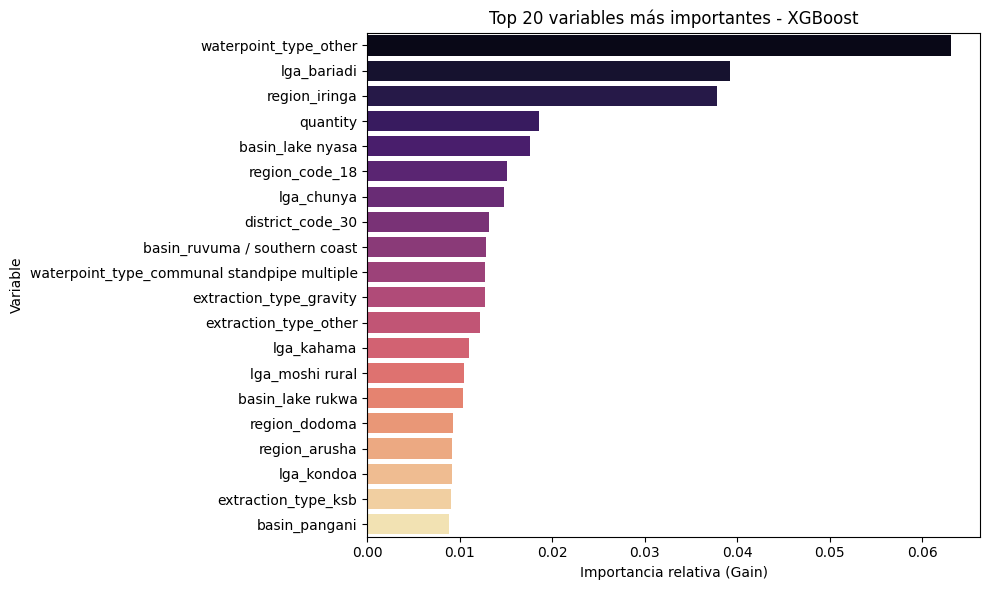

El Top 3 absoluto para XGBoost es: ['waterpoint_type_other', 'lga_bariadi', 'region_iringa']


In [ ]:
importancias_xgb = modelo_xgb.feature_importances_

df_importancias_xgb = pd.DataFrame({
    'Variable': X_train_sub.columns,
    'Importancia': importancias_xgb}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importancia',
    y='Variable',
    data=df_importancias_xgb.head(20),
    palette='magma',
    hue='Variable',
    legend=False)
plt.title('Top 20 variables más importantes - XGBoost')
plt.xlabel('Importancia relativa (Gain)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

top3_xgb = df_importancias_xgb['Variable'].head(3).tolist()
print(f"El Top 3 absoluto para XGBoost es: {top3_xgb}")

## **PREDICCIÓN Y EXPORTACIÓN XGBOOST**

XGBoost predice números (0, 1, 2) debido al `LabelEncoder` que aplicamos durante el entrenamiento, por lo que, antes de exportar el archivo CSV, debemos revertir esa transformación matemática y devolver las etiquetas a su formato de texto original.

In [ ]:
predicciones_num_xgb = modelo_xgb.predict(X_test_procesado)

predicciones_texto_xgb = le.inverse_transform(predicciones_num_xgb)

df_submission_xgb = pd.DataFrame({
    'id': ids_test,
    'status_group': predicciones_texto_xgb})

nombre_archivo_xgb = 'xgboost_submission.csv'
#df_submission_xgb.to_csv(nombre_archivo_xgb, index=False)

print(f"Archivo exportado: {nombre_archivo_xgb}")
print("-" * 40)
print("Vista previa de las predicciones de XGBoost:")
df_submission_xgb.head(5)

Archivo exportado: xgboost_submission.csv
----------------------------------------
Vista previa de las predicciones de XGBoost:


,id,status_group
0,50785,functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional
